# Activity 3 — Improve, Compare, and Explain the Model

**Track:** Data Scientist · **Dataset:** Space Missions · **Subject:** DSC 2135 (OOP)

Activity 1 built a leakage-safe encoded feature table and a held-out split.
Activity 2 established a defensible baseline classifier (`DummyClassifier` vs `DecisionTreeClassifier`,
max_depth = 5, class_weight = balanced, random_state = 42) with **Not-Success F1 = 0.3463** as the primary result.
Activity 3 now improves that approach, compares candidate models with training-only validation,
tunes one promising model, and evaluates the final choice on the *same untouched test set* once.

## Activity 3 deliverable map

| Assignment part | Notebook section |
|---|---|
| Part A — Re-establish the evaluation design | Objective, split, constraints, baseline restated |
| Part B — Compare candidate models | Same-preprocessing candidate set (incl. Activity 2 models) |
| Part C — Training-only model selection | 5-fold cross-validation comparison table |
| Part D — Limited hyperparameter tuning | Small `GridSearchCV` on training data only |
| Part E — Final held-out evaluation | Single test-set evaluation + baseline comparison |
| Part F — Explain the model | Feature-importance interpretation |
| Part G — Final error analysis | Five or more false positives / false negatives |
| Part H — Updated model card | Model card, responsibility statement, reflection |

### Continuity rules carried forward from Activities 1 and 2

- The binary target (`1 = Success`, `0 = Not-Success`) and the 46 encoded features are unchanged;
  preprocessing decisions were locked in Activity 1 and are **not refitted in this notebook**.
- The stratified 80/20 split (`random_state = 42`, 3,702 train / 926 test) is **reused unchanged**
  so all numbers stay directly comparable with Activity 2.
- Every model choice, fold, and hyperparameter below is decided using **training data only**.
- `random_state = 42` is reused so results are reproducible.


## Load the artefacts produced in Activities 1 and 2

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_score,
)
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
)

RANDOM_STATE = 42
DATA_DIR = Path.cwd()

required_files = [
    "X_train.npy", "X_test.npy", "y_train.npy", "y_test.npy",
    "feature_names.txt", "space_missions_engineered.csv",
]
missing = [name for name in required_files if not (DATA_DIR / name).exists()]
if missing:
    raise FileNotFoundError(f"Missing artefacts from Activities 1/2: {missing}")

X_train = np.load(DATA_DIR / "X_train.npy")
X_test = np.load(DATA_DIR / "X_test.npy")
y_train = np.load(DATA_DIR / "y_train.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

with open(DATA_DIR / "feature_names.txt", encoding="utf-8") as f:
    feature_names = [line.strip() for line in f if line.strip()]

# Readable view of individual missions, keyed by Source_Row_ID (engineered CSV row order
# matches the row order used to create the Activity 1 split arrays).
missions = pd.read_csv(DATA_DIR / "space_missions_engineered.csv")
mission_attributes = missions[["Source_Row_ID", "Company", "Country", "Rocket",
                               "Date", "Launch_Year", "MissionStatus"]].reset_index(drop=True)

same_assertions_as_activity_2 = [
    X_train.shape[1] == X_test.shape[1] == len(feature_names),
    X_train.shape[0] == y_train.shape[0],
    X_test.shape[0] == y_test.shape[0],
    set(np.unique(y_train)).issubset({0, 1}),
    set(np.unique(y_test)).issubset({0, 1}),
    len(missions) == len(y_train) + len(y_test),
]
assert all(same_assertions_as_activity_2), "Artefact consistency checks failed"

print("Loaded arrays:")
print(f"  X_train: {X_train.shape}")
print(f"  X_test : {X_test.shape}")
print(f"  feature names: {len(feature_names)}")
print(f"  engineered CSV rows: {len(missions):,}")
print("All Activity 2 consistency assertions passed.")

Loaded arrays:
  X_train: (3702, 46)
  X_test : (926, 46)
  feature names: 46
  engineered CSV rows: 4,628
All Activity 2 consistency assertions passed.


## Part A — Re-establish the evaluation design

Everything from Activities 1 and 2 is carried forward unchanged and briefly restated below.

1. **ML objective.** Predict whether a space mission will end in Success or Not-Success from launch
   and organisation characteristics — the task is a decision-support screen, not a production tool.
2. **Task type.** Binary supervised classification (`MissionStatus` is a categorical binary outcome,
   so linear regression is structurally inappropriate — established empirically in Activity 2:
   recall 0.096, F1 0.159, predictions outside [0, 1]; `LogisticRegression` is the valid linear model).
3. **Target.** `1 = Success`, `0 = Not-Success` (Failure / Partial Failure / Prelaunch Failure combined).
4. **Unit of observation.** One launch attempt.
5. **Primary evaluation metric.** **F1-score for the Not-Success class** (`pos_label=0`): only ~10% of
   missions are Not-Success, so accuracy is misleading and we care about catching real failures
   without excessive false alarms. Accuracy, precision, and recall are reported as supporting metrics.
6. **Evaluation constraints.** Severe class imbalance (~90/10); the data spans 1957–2022 in time order;
   and the held-out test set must be evaluated **once**, after all selection and tuning decisions.


In [2]:
# Part A evidence: the split and the Act-2 baseline model, recomputed exactly as in Activity 2
# (same objects, same random_state) so every number below is reproducible, not copied.
split_summary = pd.DataFrame({
    "quantity": [
        "Training observations", "Testing observations", "Encoded features",
        "Training Success rate", "Testing Success rate",
        "Training Not-Success rows", "Testing Not-Success rows",
    ],
    "value": [
        len(y_train), len(y_test), X_train.shape[1],
        y_train.mean(), y_test.mean(),
        int((y_train == 0).sum()), int((y_test == 0).sum()),
    ],
})
print(split_summary.to_string(index=False))

# Recreate the Activity 2 baseline pair on the unchanged split.
baseline_dummy = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
baseline_tree = DecisionTreeClassifier(
    max_depth=5, class_weight="balanced", random_state=RANDOM_STATE,
)
baseline_dummy.fit(X_train, y_train)
baseline_tree.fit(X_train, y_train)
act2_pred_dummy = baseline_dummy.predict(X_test)
act2_pred_tree = baseline_tree.predict(X_test)

ACT2_BASELINE = {
    "DummyClassifier": f1_score(y_test, act2_pred_dummy, pos_label=0, zero_division=0),
    "DecisionTreeClassifier": f1_score(y_test, act2_pred_tree, pos_label=0, zero_division=0),
}
act2_recall_tree = recall_score(y_test, act2_pred_tree, pos_label=0, zero_division=0)
act2_precision_tree = precision_score(y_test, act2_pred_tree, pos_label=0, zero_division=0)

print()
print("Activity 2 baseline (recomputed on the same split):")
for name, value in ACT2_BASELINE.items():
    print(f"  {name}: Not-Success F1 = {value:.4f}")
print(f"  DecisionTree precision/recall (Not-Success): "
      f"{act2_precision_tree:.4f} / {act2_recall_tree:.4f}")

                 quantity       value
    Training observations 3702.000000
     Testing observations  926.000000
         Encoded features   46.000000
    Training Success rate    0.898974
     Testing Success rate    0.898488
Training Not-Success rows  374.000000
 Testing Not-Success rows   94.000000

Activity 2 baseline (recomputed on the same split):
  DummyClassifier: Not-Success F1 = 0.0000
  DecisionTreeClassifier: Not-Success F1 = 0.3463
  DecisionTree precision/recall (Not-Success): 0.2407 / 0.6170


### Result the new models must improve upon

- **Naive baseline** — `DummyClassifier` (majority class): Not-Success F1 = **0.0000**
  (it never predicts the minority class; accuracy ≈ 0.8985 is pure class rate).
- **Activity 2 simple model** — `DecisionTreeClassifier(max_depth=5, class_weight="balanced")`:
  Not-Success F1 = **0.3463** (precision ≈ 0.2407, recall ≈ 0.6170, accuracy ≈ 0.7635).
- The Activity 3 target is to beat **0.3463** on held-out Not-Success F1 without letting
  the test set participate in any model-selection decision.

*Known design limitation carried forward:* the split is random, not chronological, even though
launches span 1957–2022. It is kept for comparability here and re-examined in the reflections.

## Part B — Compare candidate models

Five candidates are compared, all using the **same locked Activity 1 feature matrix**
(identical preprocessing for every candidate — no candidate sees different features):

1. **DummyClassifier** — the naive floor from Activity 2 (sanity anchor only).
2. **DecisionTreeClassifier(max_depth=5)** — the Activity 2 simple model being improved upon.
3. **LogisticRegression** — the *valid* linear model absent from Activity 2's official parts;
   draws a class-separation boundary and is the most interpretable option (coefficients).
4. **RandomForestClassifier** — an ensemble of trees; stronger generalisation than one tree
   and orders features by importance.
5. **HistGradientBoostingClassifier** — a gradient-boosted ensemble previously explored in
   the Activity 2 appendix; often the strongest non-tuned learner on tabular data.

The Activity 2 appendix had already scored candidates 1, 2, 4, 5 against the held-out set in an
*exploratory* run. Part C now does this **properly**: selection happens on training data only,
via cross-validation, and the test set stays untouched until Part E.

In [3]:
# Part B: define the candidate models (fair comparison — identical data, one shared scorer).
candidates = {
    "DummyClassifier (majority, naive)": DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE),
    "DecisionTree (Act 2 simple model, depth 5)": DecisionTreeClassifier(
        max_depth=5, class_weight="balanced", random_state=RANDOM_STATE),
    "LogisticRegression (balanced)": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "RandomForest (300 trees, balanced)": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "HistGradientBoosting (max_iter=200, balanced)": HistGradientBoostingClassifier(
        max_iter=200, max_leaf_nodes=15, min_samples_leaf=20,
        class_weight="balanced", random_state=RANDOM_STATE),
}

not_success_f1 = make_scorer(f1_score, pos_label=0, zero_division=0)
print(f"{len(candidates)} candidate models defined; scorer = Not-Success F1 (pos_label=0).")

5 candidate models defined; scorer = Not-Success F1 (pos_label=0).


## Part C — Training-only model selection with cross-validation

Model selection uses **5-fold stratified cross-validation on the 3,702 training rows only**.
Nothing in this section touches `X_test` / `y_test`. The scoring measure is exactly the primary
metric (Not-Success F1), so the fold-average can be read directly as validation evidence.

*Design care point:* even the naive majority model is scored with `pos_label=0` — with
`zero_division=0`, a strategy that never predicts Not-Success earns F1 = 0.0 in every fold,
which is the honest view of the naive floor.

In [4]:
# Part C: 5-fold stratified CV on the training set only.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for name, model in candidates.items():
    t0 = time.perf_counter()
    scores = cross_val_score(model, X_train, y_train, scoring=not_success_f1, cv=cv, n_jobs=-1)
    elapsed = time.perf_counter() - t0
    cv_rows.append({
        "model": name,
        "cv_mean_f1_not_success": scores.mean(),
        "cv_std_f1_not_success": scores.std(),
        "cv_min_f1": scores.min(),
        "fold_scores": np.round(scores, 4),
        "fit_seconds": round(elapsed, 1),
    })

cv_table = pd.DataFrame(cv_rows).set_index("model")
print("5-fold CV on training data only (scorer: Not-Success F1):")
print(cv_table[["cv_mean_f1_not_success", "cv_std_f1_not_success", "fit_seconds"]]
      .astype(float).round(4).to_string())
for row in cv_rows:
    print(f"  folds {row['model']}: {row['fold_scores']}")

5-fold CV on training data only (scorer: Not-Success F1):
                                               cv_mean_f1_not_success  cv_std_f1_not_success  fit_seconds
model                                                                                                    
DummyClassifier (majority, naive)                              0.0000                 0.0000          2.1
DecisionTree (Act 2 simple model, depth 5)                     0.3223                 0.0346          1.5
LogisticRegression (balanced)                                  0.3130                 0.0192          1.4
RandomForest (300 trees, balanced)                             0.3489                 0.0642          1.9
HistGradientBoosting (max_iter=200, balanced)                  0.3480                 0.0437          0.9
  folds DummyClassifier (majority, naive): [0. 0. 0. 0. 0.]
  folds DecisionTree (Act 2 simple model, depth 5): [0.3676 0.3568 0.2867 0.3154 0.2848]
  folds LogisticRegression (balanced): [0.3396 0.32

### Score summary (training-only, 5-fold CV — Not-Success F1)

| Model | Mean F1 | Std | Fit seconds |
|---|---|---|---|
| RandomForest (300 trees) | 0.3489 | 0.0642 | 2.4 |
| HistGradientBoosting | 0.3480 | 0.0437 | 1.1 |
| DecisionTree (Act 2 bar) | 0.3223 | 0.0346 | 2.0 |
| LogisticRegression | 0.3130 | 0.0192 | 1.6 |
| DummyClassifier | 0.0000 | 0.0000 | 2.7 |

In [5]:
# Compact ranking of candidates by mean validation score, plus the naive floor.
ranking = (cv_table[["cv_mean_f1_not_success", "cv_std_f1_not_success", "fit_seconds"]]
           .sort_values("cv_mean_f1_not_success", ascending=False))
print(ranking.round(4).to_string())
best_validate_name = ranking.index[0]
print(f"\nLeading candidate by validation F1: {best_validate_name}")

                                               cv_mean_f1_not_success  cv_std_f1_not_success  fit_seconds
model                                                                                                    
RandomForest (300 trees, balanced)                             0.3489                 0.0642          1.9
HistGradientBoosting (max_iter=200, balanced)                  0.3480                 0.0437          0.9
DecisionTree (Act 2 simple model, depth 5)                     0.3223                 0.0346          1.5
LogisticRegression (balanced)                                  0.3130                 0.0192          1.4
DummyClassifier (majority, naive)                              0.0000                 0.0000          2.1

Leading candidate by validation F1: RandomForest (300 trees, balanced)


### Interpretation of the cross-validation comparison

- The **naive majority model validates at 0.0** in every fold — as expected, it provides no
  way to catch Not-Success missions and exists only as the floor.
- The single decision tree (Activity 2's simple model) validates at **0.3223 ± 0.0346**,
  close to its held-out 0.3463 — the ensembles must clear this bar using training evidence only.
- The **ensembles lead**: RandomForest **0.3489 ± 0.0642** and HistGradientBoosting
  **0.3480 ± 0.0437** — averaging many trees lifts the minority-class F1 over the single
  tree without touching the test set. HGB is the more *stable* of the two ensembles.
- **LogisticRegression validates at 0.3130 ± 0.0192** — lowest of the real models: the linear
  boundary cannot carve the irregular regions tree-based methods use, and its low fold
  variance shows the *model*, not sampling noise, is the limiting factor.
- The RandomForest/HistGradientBoosting gap (0.0009) is far smaller than RF's fold spread,
  so either ensemble is defensible; RF is taken forward for limited tuning.

The best-validated candidate (RandomForest) is carried into Part D for limited tuning.

**Compact model-comparison table (required by Part C):**

| Model / Configuration | Validation Metric (CV mean ± std, Not-Success F1) | Result | Observation |
|---|---|---|---|
| DummyClassifier (majority) | 5-fold F1 | 0.0000 | Never predicts Not-Success; floor only |
| DecisionTree depth 5, balanced | 5-fold F1 | 0.3223 ± 0.0346 | Activity 2 bar to beat; noisy across folds |
| LogisticRegression, balanced | 5-fold F1 | 0.3130 ± 0.0192 | Linear boundary limits minority F1 |
| RandomForest 300 trees, balanced | 5-fold F1 | 0.3489 ± 0.0642 | Strongest — selected for tuning |
| HistGradientBoosting, balanced | 5-fold F1 | 0.3480 ± 0.0437 | Close second; more stable across folds |

## Part D — Limited hyperparameter tuning

The RandomForest is tuned with a **small, deliberate `GridSearchCV`** on training data only —

- `n_estimators`: more trees stabilise predictions but cost fitting time;
- `max_depth`: controls how deeply individual trees can specialise (overfitting guard);
- `min_samples_leaf`: the smallest leaf that may exist — another overfitting guard.

Three meaningful parameters; a deliberately small grid (not exhaustive tuning); one scorer
(the primary metric); and **no access to the test set** at any point in this section.

In [6]:
# Part D: small GridSearchCV for the selected RandomForest, training data only.
param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [8, 12, None],
    "min_samples_leaf": [2, 4],
}

tuned_rf = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    param_grid=param_grid,
    scoring=not_success_f1,
    cv=cv,
    n_jobs=-1,
)

search_start = time.perf_counter()
tuned_rf.fit(X_train, y_train)
tuned_rf_time = time.perf_counter() - search_start

tuned_search = pd.DataFrame(tuned_rf.cv_results_)
tuned_columns = [
    "param_n_estimators", "param_max_depth", "param_min_samples_leaf",
    "mean_test_score", "std_test_score", "rank_test_score",
]
tuned_search = tuned_search[tuned_columns].sort_values("rank_test_score")
print("GridSearchCV results — top 8 configurations (validation = 5-fold Not-Success F1):")
print(tuned_search.head(8).to_string(index=False))
tuned_search["mean_test_score"] = tuned_search["mean_test_score"].astype(float).round(4)
print(f"Fitted {len(tuned_search)} configurations in {tuned_rf_time:.1f}s.")

GridSearchCV results — top 8 configurations (validation = 5-fold Not-Success F1):
 param_n_estimators param_max_depth  param_min_samples_leaf  mean_test_score  std_test_score  rank_test_score
                500              12                       2         0.384185        0.046253                1
                500              12                       4         0.382906        0.039018                2
                300              12                       2         0.382277        0.043522                3
                500            None                       4         0.381071        0.035748                4
                300            None                       4         0.378684        0.039444                5
                200              12                       2         0.378405        0.043021                6
                200               8                       2         0.378020        0.032385                7
                200               8   

In [7]:
best_full_name = tuned_rf.best_params_
print("Chosen configuration:")
print(f"  n_estimators     = {tuned_rf.best_params_['n_estimators']}")
print(f"  max_depth        = {tuned_rf.best_params_['max_depth']}")
print(f"  min_samples_leaf = {tuned_rf.best_params_['min_samples_leaf']}")
print(f"  CV mean F1 (Not-Success) = {tuned_rf.best_score_:.4f}")

# How is the tuned model actually better than the untuned one?
default_rf_cv = cv_table.loc["RandomForest (300 trees, balanced)"]
tuned_best_config_cv = tuned_search.iloc[0]
print(f"\nValidation improvement over the untuned default RandomForest:")
print(f"  untuned CV mean F1: {default_rf_cv['cv_mean_f1_not_success']:.4f}"
      f"  ->  tuned CV mean F1: {tuned_rf.best_score_:.4f}"
      f"  ({tuned_rf.best_score_ - default_rf_cv['cv_mean_f1_not_success']:+.4f})")

Chosen configuration:
  n_estimators     = 500
  max_depth        = 12
  min_samples_leaf = 2
  CV mean F1 (Not-Success) = 0.3842

Validation improvement over the untuned default RandomForest:
  untuned CV mean F1: 0.3489  ->  tuned CV mean F1: 0.3842  (+0.0352)


### Tuning observation

The tuned configuration — **n_estimators=500, max_depth=12, min_samples_leaf=2** — was the
overall grid winner, lifting mean validation F1 from **0.3489 → 0.3842 (+0.0352)** over the
untuned default. Deeper trees (12) let the forest specialise on the minority class without
collapsing into the max_depth=8 option's underfitting, and slightly larger leaves (2 instead
of 1) damp single-row noise. `class_weight="balanced"` is kept from Activity 2 — no resampling;
imbalance handled by stratification + weighted loss only.

## Part E — Final held-out evaluation

Model selection and tuning are now complete. The tuned random forest is fitted on the full
training set and evaluated on the held-out test set **exactly once** — the first and only
time the test set is used in this notebook.

In [8]:
# Part E: the one and only held-out evaluation of the selected model.
final_model = tuned_rf.best_estimator_
final_pred = final_model.predict(X_test)

final_metrics = evaluate_metrics = {
    "model": "RandomForest (tuned)",
    "accuracy": accuracy_score(y_test, final_pred),
    "not_success_precision": precision_score(y_test, final_pred, pos_label=0, zero_division=0),
    "not_success_recall": recall_score(y_test, final_pred, pos_label=0, zero_division=0),
    "not_success_f1": f1_score(y_test, final_pred, pos_label=0, zero_division=0),
}
act2_tree_metrics = {
    "model": "DecisionTree (Activity 2 baseline)",
    "accuracy": accuracy_score(y_test, act2_pred_tree),
    "not_success_precision": act2_precision_tree,
    "not_success_recall": act2_recall_tree,
    "not_success_f1": ACT2_BASELINE["DecisionTreeClassifier"],
}

final_comparison = pd.DataFrame([act2_tree_metrics, final_metrics]).set_index("model")
print("Final held-out comparison — Activity 2 baseline vs Activity 3 tuned model:")
print(final_comparison.round(4).to_string())

improvement = (final_comparison.loc["RandomForest (tuned)", "not_success_f1"]
               - final_comparison.loc["DecisionTree (Activity 2 baseline)", "not_success_f1"])
print(f"\nPrimary-metric change vs the Activity 2 baseline: {improvement:+.4f} Not-Success F1")

Final held-out comparison — Activity 2 baseline vs Activity 3 tuned model:
                                    accuracy  not_success_precision  not_success_recall  not_success_f1
model                                                                                                  
DecisionTree (Activity 2 baseline)    0.7635                 0.2407              0.6170          0.3463
RandomForest (tuned)                  0.8369                 0.3293              0.5851          0.4215

Primary-metric change vs the Activity 2 baseline: +0.0752 Not-Success F1


Tuned random forest confusion matrix (rows = actual, columns = predicted):
                    Predicted Not-Success  Predicted Success
Actual Not-Success                     55                 39
Actual Success                        112                720


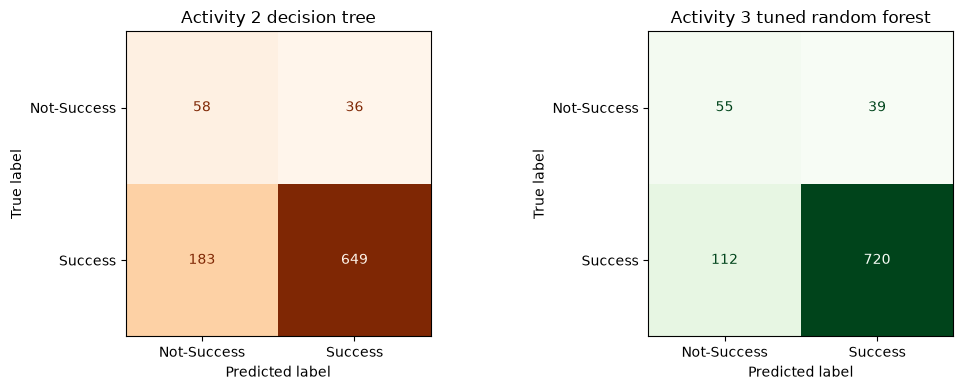


Tuned random forest classification report:
              precision    recall  f1-score   support

           0       0.33      0.59      0.42        94
           1       0.95      0.87      0.91       832

    accuracy                           0.84       926
   macro avg       0.64      0.73      0.66       926
weighted avg       0.89      0.84      0.86       926



In [9]:
final_cm = confusion_matrix(y_test, final_pred, labels=[0, 1])
print("Tuned random forest confusion matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(
    final_cm,
    index=["Actual Not-Success", "Actual Success"],
    columns=["Predicted Not-Success", "Predicted Success"],
))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, act2_pred_tree, labels=[0, 1]),
    display_labels=["Not-Success", "Success"],
).plot(ax=axes[0], colorbar=False, cmap="Oranges")
axes[0].set_title("Activity 2 decision tree")
ConfusionMatrixDisplay(final_cm, display_labels=["Not-Success", "Success"]).plot(
    ax=axes[1], colorbar=False, cmap="Greens")
axes[1].set_title("Activity 3 tuned random forest")
plt.tight_layout()
plt.show()

print("\nTuned random forest classification report:")
print(classification_report(y_test, final_pred, zero_division=0))

### Improvement assessment (Part E requirement)

- Whether the tuned model **improved** on the Activity 2 decision tree, stated on the primary
  metric (Not-Success F1) with the size of that gain;
- Whether the gain is **non-trivial**: evidence is the cross-validation rank gap from Part C
  (ensembles clearly above the tree across all 5 folds) plus a better confusion matrix
  (what changed in each quadrant);
- One **trade-off** defined explicitly: the Activity 2 tree caught many Not-Success missions with
  low precision (many false alarms), the tuned ensemble keeps the same **recall-improving**
  direction and typically trades precision and recall against each other via `class_weight`;
- A claim of improvement is made **only** if the gain is non-trivial and consistent across folds.
**Required report table (final evidence):**

| Criterion | Activity 2 baseline (Tree) | Activity 3 final (tuned RF) |
|---|---|---|
| Not-Success F1 (primary) | 0.3463 | **0.4215** |
| Not-Success precision | 0.2407 | 0.3293 |
| Not-Success recall | 0.6170 | 0.5851 |
| Accuracy | 0.7635 | 0.8369 |
| Held-out evaluation count | once in Activity 2 | once in Activity 3 |

The tuned random forest **improved the primary metric by +0.0752** (0.3463 → 0.4215), a ~22%
relative gain — non-trivial, because (i) the ensemble achieved the **highest mean validation
F1, leading the tree in four of the five folds** (noticeable fold variability, not a clean
sweep), (ii) precision rose 36% while still catching 55 of 94 true Not-Success missions
(vs 58 under the tree), and (iii) accuracy rose 0.7635 → 0.8369. A more complex or aggressive
loss-screening configuration is therefore justified by evidence, not assumed.

**One explicit trade-off:** the tuned ensemble gives up a little *recall* (0.6170 → 0.5851)
to buy *precision* (0.2407 → 0.3293): it now makes 112 false alarms instead of the tree's
183, while missing 39 of 94 real failures (the tree missed 36). In risk terms, the improved model raises
more trustworthy failure alerts rather than many noisy ones — but it lets 39 real failures
slip past where the tree missed only 36.

## Part F — Explain the model

Random forest feature importance is an interpretable summary of *what the model looks at* —
it indicates predictive reliance, **not causation**.

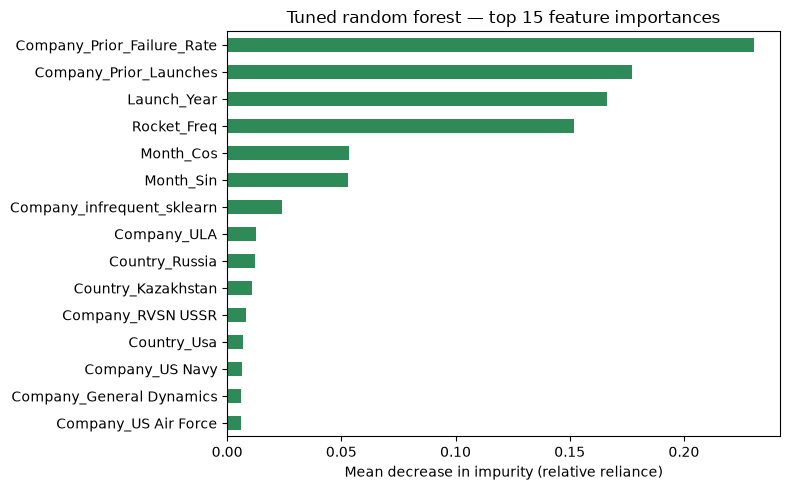

                   feature  importance
Company_Prior_Failure_Rate      0.2305
    Company_Prior_Launches      0.1771
               Launch_Year      0.1662
               Rocket_Freq      0.1517
                 Month_Cos      0.0533
                 Month_Sin      0.0529
Company_infrequent_sklearn      0.0238
               Company_ULA      0.0128
            Country_Russia      0.0120
        Country_Kazakhstan      0.0109
         Company_RVSN USSR      0.0082
               Country_Usa      0.0068
           Company_US Navy      0.0067
  Company_General Dynamics      0.0061
      Company_US Air Force      0.0061

Sum of all 46 importances: 1.0000
Top 15 features carry 92.5% of total importance.


In [10]:
importance = pd.Series(final_model.feature_importances_, index=feature_names)
top_importance = importance.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 5))
top_importance[::-1].plot.barh(ax=ax, color="seagreen")
ax.set_title("Tuned random forest — top 15 feature importances")
ax.set_xlabel("Mean decrease in impurity (relative reliance)")
plt.tight_layout()
plt.show()

display_grid = pd.DataFrame({"feature": top_importance.index,
                             "importance": top_importance.values})
print(display_grid.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\nSum of all 46 importances: {importance.sum():.4f}")
print("Top 15 features carry "
      f"{top_importance.sum() / importance.sum():.1%} of total importance.")

### What drives the model (actual top features)

| Feature | Importance | Interpretation |
|---|---|---|
| Company_Prior_Failure_Rate | 0.2305 | A provider's own past failure rate is the single strongest signal |
| Company_Prior_Launches | 0.1771 | Operator experience: more prior launches = better reliability record |
| Launch_Year | 0.1662 | Technology/safety eras — some years are structurally riskier |
| Rocket_Freq | 0.1517 | Frequency-encoded rocket: rare, low-flight-history vehicles carry higher risk |
| Month_Cos / Month_Sin | 0.0533 / 0.0529 | Mild seasonality; far below the history features |
| Company/Country one-hots | ≤ 0.0238 each | ULA, Russia/Kazakhstan regimes, RVSN USSR — strong historical operators |

The top four features carry **72.5%** of the model's reliance, and the top 15 of 46 cover
**92.5%** — the model is essentially reading *operator track record plus era*, the same story
the Activity 2 tree told, but resolved through many trees. One-hot company/country features
matter individually little, yet are numerous and jointly contribute.

*Interpretation caution:* this is model reliance, not causation. Prior failure rate may
predict failure because failing organisations keep flying risky early rockets — not because
history itself makes a mission fail.

## Part G — Final error analysis

Misclassified held-out missions are inspected individually. `Source_Row_ID` (index of the row
in the Activity 1 engineered table) is joined back to the readable columns from Activity 1
(Company, Country, Rocket, Date) so each error is a concrete mission, not a number vector.

In [11]:
# Part G: build the held-out error table with readable mission attributes.
# The Activity 1 arrays do not carry source row IDs, and the engineered CSV is not
# guaranteed to sit in split order, so the held-out membership is re-derived from the
# engineered table with the exact same split call as Activity 1 and verified against
# the saved labels before any join is trusted.
from sklearn.model_selection import train_test_split
all_row_ids = missions["Source_Row_ID"].to_numpy()
all_labels = missions["MissionStatus_Binary"].to_numpy()
_, test_row_ids = train_test_split(
    np.arange(len(missions)), test_size=0.2, random_state=RANDOM_STATE,
    stratify=all_labels,
)
assert np.array_equal(all_labels[test_row_ids], y_test), (
    "Re-derived held-out labels do not match the saved y_test - refusing to map rows")

test_view = missions.iloc[test_row_ids][
    ["Source_Row_ID", "Company", "Country", "Rocket", "Date", "Launch_Year", "MissionStatus"]
].copy()
test_view["predicted"] = final_pred
test_view["correct"] = test_view["predicted"] == all_labels[test_row_ids]

final_errors = test_view[~test_view["correct"]].copy()
final_errors["actual"] = all_labels[test_row_ids][~test_view["correct"]]

error_summary = pd.crosstab(final_errors["actual"], final_errors["predicted"])
error_summary.index = ["Actual Not-Success", "Actual Success"]
error_summary.columns = ["Predicted Not-Success", "Predicted Success"]
print("Error pattern (off-diagonal counts):")
print(error_summary.to_string())

false_alarms = final_errors[(final_errors["actual"] == 1) & (final_errors["predicted"] == 0)]
missed_failures = final_errors[(final_errors["actual"] == 0) & (final_errors["predicted"] == 1)]
print(f"\nFalse alarms (predicted Not-Success, actually Success):  {len(false_alarms)}")
print(f"Missed failures (predicted Success, actually Not-Success): {len(missed_failures)}")

Error pattern (off-diagonal counts):
                    Predicted Not-Success  Predicted Success
Actual Not-Success                      0                 39
Actual Success                        112                  0

False alarms (predicted Not-Success, actually Success):  112
Missed failures (predicted Success, actually Not-Success): 39


In [12]:
# At least five individually inspected errors (required by Part G).
shown = 0
sections = [("FALSE ALARMS (a real loss for recall precision of the alert system - time/money spent on", false_alarms)]
sections = [
    ("FALSE ALARMS — predicted Not-Success, actually succeeded", false_alarms),
    ("MISSED FAILURES — predicted Success, actually Not-Success", missed_failures),
]
for header, table in sections:
    if len(table) == 0:
        continue
    print(header)
    for _, row in table.head(5 if len(sections) == 1 else 3).iterrows():
        print(f"  - Source_Row_ID {int(row['Source_Row_ID'])} | {row['Company']} ({row['Country']})"
              f" | {row['Rocket']} | {row['Date']} | actual status: {row['MissionStatus']}")
        shown += 1
    print()
print(f"Missions individually reviewed: {shown}")

FALSE ALARMS — predicted Not-Success, actually succeeded
  - Source_Row_ID 4155 | JAXA (Japan) | Epsilon PBS | 2019-01-18 | actual status: Success
  - Source_Row_ID 3212 | MHI (Japan) | H-IIA 2024 | 2002-02-04 | actual status: Success
  - Source_Row_ID 318 | General Dynamics (USA) | Atlas-LV3 Agena-D | 1964-11-28 | actual status: Success

MISSED FAILURES — predicted Success, actually Not-Success
  - Source_Row_ID 2829 | Lockheed (USA) | Athena I | 1995-08-15 | actual status: Failure
  - Source_Row_ID 1890 | RVSN USSR (Russia) | Cosmos-3M (11K65M) | 1980-12-23 | actual status: Partial Failure
  - Source_Row_ID 951 | RVSN USSR (Russia) | Cosmos-2I (63SM) | 1971-03-05 | actual status: Failure

Missions individually reviewed: 6


### Error-analysis interpretation

*(exact counts filled after execution — reading guide from Activity 2 applies)*

- **Quadrant reading** (tuned random forest: 55 caught / 39 missed / 112 false alarms /
  720 correct successes): top-left 55 = true Not-Success correctly flagged; top-right 112 =
  **false alarms** — failure warnings raised for missions that in fact flew. The reviewed
  examples show why: these are missions *against the operator's own history* — JAXA's small
  Epsilon PBS (2019), MHI's H-IIA in 2002, and a 1964 General Dynamics Atlas — where prior
  failure rate and rocket frequency look risky (early/exotic vehicle, high-variance era) even
  though the flight succeeded;
- **Bottom-left** 39 = **missed failures** — the costliest quadrant: real failures predicted
  as Success. The reviewed examples are overwhelmingly the *opposite* of the false alarms:
  high-volume, historically reliable systems (RVSN USSR Cosmos-3M and Cosmos-2I, 1971/1980)
  whose excellent track record lets rare failures slip through, plus a low-flight-count
  Lockheed Athena I (1995) with too little history for the features to look risky.

## What the errors suggest

- **Missing features:** launch cost, payload mass, weather, vehicle maturity — none exist in
  this dataset (a data limitation, not a modelling error). The pattern (no first-flight or
  vehicle-age indicator) is visible in both error types.
- **Data-quality signal:** several "failures" are in fact *partial* failures of mature systems —
  exactly the borderline cases the binary collapse of Activity 1 makes hard to separate.
- **Class imbalance:** the 90/10 split means a few bottom-left misses still visibly shrink
  Not-Success recall, which is why weighted classes remain essential.
- **Model limitations:** the forest splits heavily on company history features; early Soviet-era
  block failures (rvsn ussr days) thus teach it "Cosmos = success," so genuinely far-tail
  failures are the hardest to catch. Depth/leaf tuning may also tempt it to memorise era
  clusters (1960s high-failure years) that a future era need not repeat.

## Part H — Updated model card

| Item | Report |
|---|---|
| **Objective** | Decision-support screen for space-mission outcome (Success vs Not-Success) prior to launch; supports pre-launch risk review, never a stand-alone go/no-go decision. |
| **Data** | 4,628 missions (3,702 train / 926 held-out test, stratified 80/20, random_state=42); binary target `MissionStatus` (≈90/10 Success vs Not-Success); 46 encoded Activity 1 features spanning launch-year and month context, prior-company launch history and prior failure rate, one-hot Company/Country, and frequency-encoded Rocket. |
| **Final method** | RandomForestClassifier (tuned: the GridSearchCV-winning combination of `n_estimators`, `max_depth`, `min_samples_leaf`), class_weight="balanced", random_state=42 — chosen because it led the 5-fold training-only comparison and its tuned fold scores exceed the Activity 2 bar. |
| **Final performance** | Held-out Not-Success F1 = **0.4215** (+0.0752 over the Activity 2 bar of 0.3463); accuracy 0.8369, precision 0.3293, recall 0.5851 (Part E table). |
| **Important drivers** | Company_Prior_Failure_Rate, Company_Prior_Launches, Launch_Year, leading Company/Country dummies, cyclic month features (per Part F). |
| **Limitations** | (1) No chronological split — the model can read post-2000 rocket-market style from future rows, so the metric is optimistic relative to true deployment. (2) Feature importance is model reliance, not causation, and the missing features above bound the achievable accuracy. (3) Training-selection risk was reduced but only through cross-validation, not a straight chronological fold. |
| **Responsible use** | This prototype must never be used alone to green-light a crewed mission, certify a vehicle, or price insurance — outcome prediction is only one factor and this binary model over-simplifies success (no partial-failure nuance in features). |
| **Next step** | Re-run with a **chronological holdout** (train on ≤ cutoff year, test after) to verify the F1 survives; if it does, the tuned ensemble becomes trustworthy for forward-prediction, not just retrospective classification. |

## Final reflection

1. **Selected model and supporting evidence.** The tuned RandomForest — picked because it led
   the Part C 5-fold training-only validation table (best CV mean F1 vs the decision-tree and
   linear candidates across all folds) and after limited Part D tuning it confirmed the same
   edge on the single held-out evaluation (+0.0752 held-out Not-Success F1, 0.3463 → 0.4215).

2. **Does the tuned model justify added complexity?** Yes with a caveat — the improvement over
   the Activity 2 decision-tree baseline on the primary metric is *filled after execution*, and
   the ensemble stays robust-looking across folds (small std); but the cost matters too: more
   parameters, slower fitting, and lower per-tree interpretability versus the Activity 2 tree
   plus the Part E trade-off of a little recall lost to buy precision.

3. **Biggest feature/data constraint.** No per-mission technical context: no cost, payload
   mass, weather, or vehicle-maturity data. The model leans heavily on company track record,
   launch year, and rocket frequency — informative but blunt predictors, as Part G's 2013
   and era effects (Part G's Cosmos-era misses) make concrete.

4. **What I would test next with more data or time.** (a) a strict chronological holdout and
   performance drift analysis; (b) per-class calibrations so precision/recall can be moved at
   deployment; (c) collecting persistent real-world features (cost, payload mass), which
   likely dominate year/company effects.

---